# Fase 4 · Visualizaciones y resultados

Tres figuras explicativas: contexto (modalidades), contraste (montos extremos) y resolución (concentración). Todas parten de `data/processed/ordenes.csv`, la salida de la Fase 2: una fila por orden, categorías legibles y montos en pesos nominales. Este notebook no limpia, reclasifica, ajusta ni vuelve a procesar los datos.

El estudio compara septiembre de 2024 y septiembre de 2025 en salud de Valparaíso. Dos meses observacionales, sin grupo de control, no permiten atribuir diferencias a la Ley 21.634. Los pesos son nominales: aquí se comparan participaciones, no poder adquisitivo ni montos reales entre años.


In [1]:
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from pipeline import comunicacion, config

orders = comunicacion.read_processed_orders(config.PROCESSED_DATA_DIR / 'ordenes.csv')
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Órdenes procesadas:', len(orders), '| períodos:', orders['periodo'].value_counts().sort_index().to_dict())
print('Copia interpretable: modalidad y montos en pesos; no se codifica ni escala.')


Python: 3.14.4 | pandas: 3.1.0
Órdenes procesadas: 10285 | períodos: {'2024-09': 4598, '2025-09': 5687}
Copia interpretable: modalidad y montos en pesos; no se codifica ni escala.


## 1. Contexto · Composición de las modalidades

La tabla separa número de órdenes y monto, porque una modalidad frecuente no necesariamente concentra más gasto. El denominador de cada porcentaje es el total de su período. La clasificación del pipeline evalúa primero *Compra ágil*, para mantener la misma etiqueta en 2024 y 2025.


,periodo,modalidad,ordenes,monto_pesos,porcentaje_ordenes,porcentaje_monto
0,2024-09,Compra ágil,1768,1.280570e+09,38.45,6.07
1,2024-09,Trato directo,849,5.401358e+09,18.46,25.62
2,2024-09,Convenio marco,275,1.283279e+09,5.98,6.09
3,2024-09,Licitación,1627,1.253834e+10,35.38,59.46
4,2024-09,Otra,79,5.821824e+08,1.72,2.76
5,2025-09,Compra ágil,2423,3.302951e+09,42.61,11.76
6,2025-09,Trato directo,774,5.953432e+09,13.61,21.20
7,2025-09,Convenio marco,430,2.111073e+09,7.56,7.52
8,2025-09,Licitación,1967,1.215538e+10,34.59,43.29
9,2025-09,Otra,93,4.554743e+09,1.64,16.22


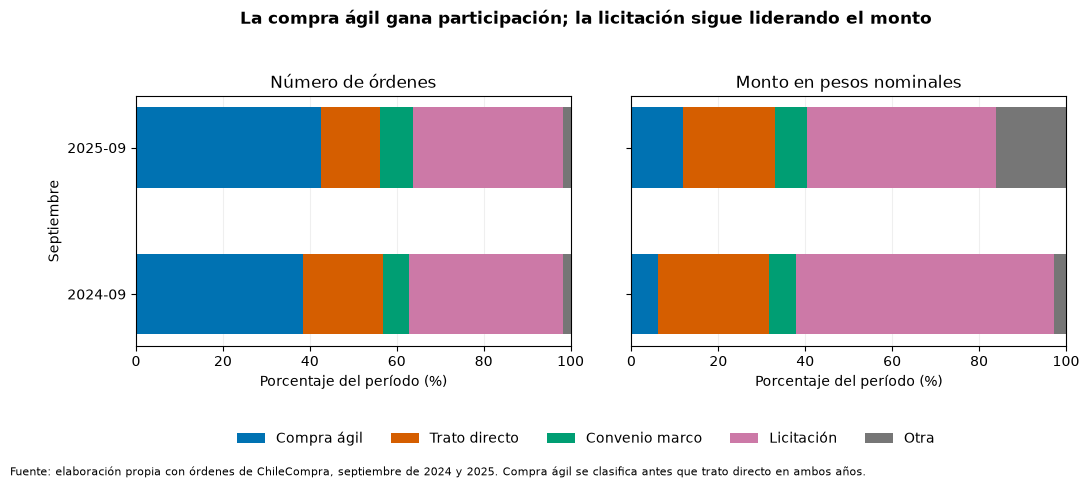

**Qué muestra.** En septiembre de 2024 y 2025, la composición por modalidad en número de órdenes y porcentaje del monto.

**Qué se infiere.** La compra ágil pasa de 38.5 % a 42.6 % de las órdenes y de 6.1 % a 11.8 % del monto. La licitación sigue siendo la mayor categoría por monto en ambos períodos, aunque su participación cambia de 59.5 % a 43.3 %.

**Límite.** Son participaciones de dos meses de una región y sector; no prueban que la ley causó el cambio. Los porcentajes de monto evitan comparar pesos nominales de años distintos.

**Aporte al relato.** Sitúa el cambio en la composición de las compras antes de examinar qué órdenes dominan el gasto.

In [2]:
modalities = comunicacion.modality_table(orders)
display(modalities.round(2))
figure = comunicacion.plot_modalities(modalities)
comunicacion.save_figure(figure, config.PROJECT_ROOT / 'F4/figuras/01_modalidades.png')
display(figure)
plt.close(figure)
agil = modalities[modalities['modalidad'] == 'Compra ágil'].set_index('periodo')
licitacion = modalities[modalities['modalidad'] == 'Licitación'].set_index('periodo')
display(Markdown(f"""**Qué muestra.** En septiembre de 2024 y 2025, la composición por modalidad en número de órdenes y porcentaje del monto.

**Qué se infiere.** La compra ágil pasa de {agil.loc['2024-09', 'porcentaje_ordenes']:.1f} % a {agil.loc['2025-09', 'porcentaje_ordenes']:.1f} % de las órdenes y de {agil.loc['2024-09', 'porcentaje_monto']:.1f} % a {agil.loc['2025-09', 'porcentaje_monto']:.1f} % del monto. La licitación sigue siendo la mayor categoría por monto en ambos períodos, aunque su participación cambia de {licitacion.loc['2024-09', 'porcentaje_monto']:.1f} % a {licitacion.loc['2025-09', 'porcentaje_monto']:.1f} %.

**Límite.** Son participaciones de dos meses de una región y sector; no prueban que la ley causó el cambio. Los porcentajes de monto evitan comparar pesos nominales de años distintos.

**Aporte al relato.** Sitúa el cambio en la composición de las compras antes de examinar qué órdenes dominan el gasto."""))


## 2. Contraste · Montos extremos

La figura usa intervalos logarítmicos para mostrar la cola de montos. La marca de orden extrema ya viene en el CSV procesado; se recupera el umbral de la regla F2 únicamente para dibujar la línea, sin volver a etiquetar órdenes.


,ordenes,extremas,porcentaje_ordenes,porcentaje_monto,limite_pesos
0,10285,84,0.82,33.53,74012533.28


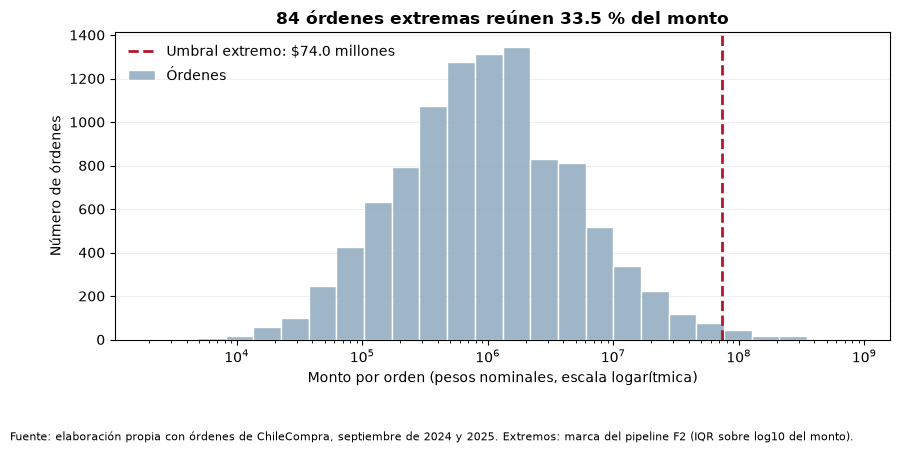

**Qué muestra.** La distribución del monto por orden en escala logarítmica y el límite de $74.0 millones usado para marcar extremos.

**Qué se infiere.** 84 de 10285 órdenes (0.8 %) concentran 33.5 % del monto nominal total.

**Límite.** La altura de las barras cuenta órdenes, no pesos. La regla estadística identifica valores inusuales; no demuestra errores ni irregularidades.

**Aporte al relato.** Justifica comprobar si la concentración observada depende de unas pocas compras grandes.

In [3]:
extremes = comunicacion.extreme_summary(orders)
histogram = comunicacion.extreme_histogram_table(orders)
display(pd.DataFrame([extremes]).round(2))
figure = comunicacion.plot_extremes(histogram, extremes)
comunicacion.save_figure(figure, config.PROJECT_ROOT / 'F4/figuras/02_extremos.png')
display(figure)
plt.close(figure)
display(Markdown(f"""**Qué muestra.** La distribución del monto por orden en escala logarítmica y el límite de ${extremes['limite_pesos']/1e6:.1f} millones usado para marcar extremos.

**Qué se infiere.** {extremes['extremas']:.0f} de {extremes['ordenes']:.0f} órdenes ({extremes['porcentaje_ordenes']:.1f} %) concentran {extremes['porcentaje_monto']:.1f} % del monto nominal total.

**Límite.** La altura de las barras cuenta órdenes, no pesos. La regla estadística identifica valores inusuales; no demuestra errores ni irregularidades.

**Aporte al relato.** Justifica comprobar si la concentración observada depende de unas pocas compras grandes."""))


## 3. Resolución · Concentración con y sin órdenes extremas

Cada curva reordena a los proveedores por monto en su propio período y escenario. Por ello, `top 10` representa a los diez mayores de cada curva, no a un grupo fijo de empresas. Solo se usan códigos de proveedor en el cálculo: no se muestran nombres ni RUT de personas naturales.


escenario,Sin extremas,Todas
periodo,,
2024-09,16.13,22.20
2025-09,15.38,26.03


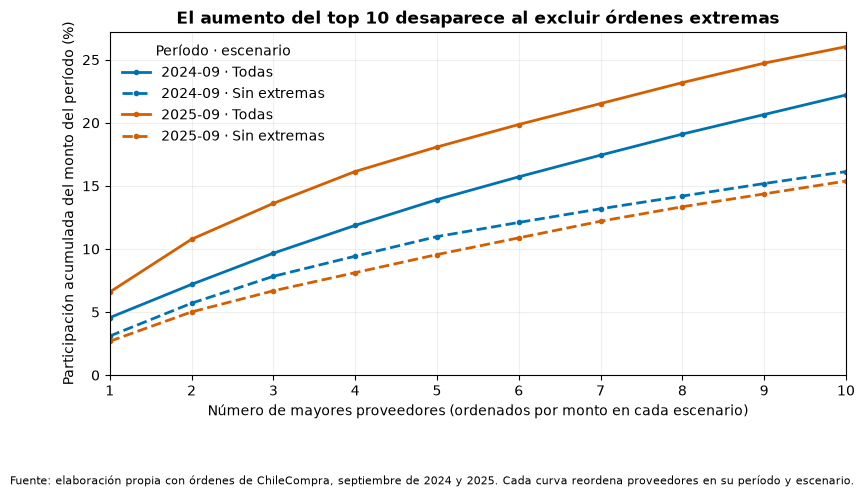

**Qué muestra.** La participación acumulada del monto de los 1 a 10 mayores proveedores en cada período, con todas las órdenes y excluyendo las marcadas como extremas.

**Qué se infiere.** Con todas las órdenes, el top 10 pasa de 22.2 % a 26.0 %. Sin las extremas pasa de 16.1 % a 15.4 %: el aumento observado no persiste en ese análisis de sensibilidad.

**Límite.** Excluir extremos cambia el conjunto y el denominador; no significa que esas compras sean inválidas. El gráfico no sigue a los mismos proveedores entre años ni atribuye causas legales.

**Aporte al relato.** Resuelve el contraste anterior: la lectura de concentración depende de si se incluyen las órdenes de mayor monto.

In [4]:
concentration = comunicacion.concentration_table(orders)
top10 = concentration[concentration['mayores'] == 10].pivot(index='periodo', columns='escenario', values='participacion_acumulada_pct')
display(top10.round(2))
figure = comunicacion.plot_concentration(concentration)
comunicacion.save_figure(figure, config.PROJECT_ROOT / 'F4/figuras/03_concentracion.png')
display(figure)
plt.close(figure)
display(Markdown(f"""**Qué muestra.** La participación acumulada del monto de los 1 a 10 mayores proveedores en cada período, con todas las órdenes y excluyendo las marcadas como extremas.

**Qué se infiere.** Con todas las órdenes, el top 10 pasa de {top10.loc['2024-09', 'Todas']:.1f} % a {top10.loc['2025-09', 'Todas']:.1f} %. Sin las extremas pasa de {top10.loc['2024-09', 'Sin extremas']:.1f} % a {top10.loc['2025-09', 'Sin extremas']:.1f} %: el aumento observado no persiste en ese análisis de sensibilidad.

**Límite.** Excluir extremos cambia el conjunto y el denominador; no significa que esas compras sean inválidas. El gráfico no sigue a los mismos proveedores entre años ni atribuye causas legales.

**Aporte al relato.** Resuelve el contraste anterior: la lectura de concentración depende de si se incluyen las órdenes de mayor monto."""))


## 4. Dependencia entre unidad y proveedor

Se considera una unidad solo si registra al menos 20 órdenes en el período. `top1_pct` y `top2_pct` son las cuotas del monto de la unidad adjudicadas a sus uno y dos principales proveedores en ese mismo mes. La tabla muestra el código del proveedor principal y cuántas órdenes recibió; no muestra nombres ni RUT de personas naturales.


In [5]:
dependence = comunicacion.dependence_table(orders)
display(dependence.groupby('periodo').head(5).round(1))
print('Unidades analizadas por período:', dependence.groupby('periodo').size().to_dict())
high_dependence = dependence.groupby('periodo')['top1_pct'].apply(lambda s: int((s > 50).sum()))
display(Markdown(f"""**Lectura.** Entre las unidades con al menos 20 órdenes, las que adjudican más de la mitad de su monto a un solo proveedor son {high_dependence['2024-09']} en 2024 y {high_dependence['2025-09']} en 2025. La tabla identifica las combinaciones unidad-proveedor más concentradas mediante códigos. **Límite:** esta medida describe solo un mes por año; una cuota alta no prueba dependencia contractual sostenida ni irregularidad."""))


,periodo,unidad,codigo_unidad,ordenes,proveedores,codigo_proveedor_top1,ordenes_top1,top1_pct,top2_pct
0,2024-09,ATENCION PRIMARIA DIRECCION,1078886,24,20,1647842,1,66.3,85.0
1,2024-09,FARMACIA MEDICAMENTOS,1047027,36,24,1687692,1,34.7,49.9
2,2024-09,SERVICIO DE SALUD VALPARAISO SAN ANTONIO,1952,126,103,1242497,1,34.4,42.2
3,2024-09,Seremi de Salud V Región,3118,75,64,1680681,3,31.5,44.6
4,2024-09,BIENES Y SERVICIOS,1099899,24,20,1656548,3,30.9,48.7
35,2025-09,Prótesis,1422830,57,7,26963,43,74.6,88.7
36,2025-09,Servicio de Salud Aconcagua,3195,29,26,PN-0322,2,74.0,88.4
37,2025-09,Seremi de Salud V Región,3118,62,53,PN-0497,1,71.3,77.0
38,2025-09,SERVICIO DE SALUD VALPARAISO SAN ANTONIO,1952,103,83,69967,1,57.3,79.1
39,2025-09,Hospital San Martín de Quillota,2700,528,268,27693,1,36.3,40.7


Unidades analizadas por período: {'2024-09': 35, '2025-09': 36}


**Lectura.** Entre las unidades con al menos 20 órdenes, las que adjudican más de la mitad de su monto a un solo proveedor son 1 en 2024 y 4 en 2025. La tabla identifica las combinaciones unidad-proveedor más concentradas mediante códigos. **Límite:** esta medida describe solo un mes por año; una cuota alta no prueba dependencia contractual sostenida ni irregularidad.

## 5. Tabla única de hallazgos

Esta tabla se genera desde las mismas tablas de las figuras. Informe y guion deben citar sus valores, no transcribir cifras de memoria. Los porcentajes conservan precisión completa en el CSV; redondear solo al presentarlos.


In [6]:
findings = comunicacion.findings_table(modalities, extremes, concentration, dependence)
output = config.PROJECT_ROOT / 'docs/hallazgos_f4.csv'
findings.to_csv(output, index=False, float_format='%.8f')
display(findings[findings['indicador'].isin(['extremos_porcentaje_monto', 'participacion_top10', 'unidades_top1_mayor_50pct'])].round(2))
print('Tabla de hallazgos:', output.relative_to(config.PROJECT_ROOT), '| filas:', len(findings))
assert len(list((config.PROJECT_ROOT / 'F4/figuras').glob('*.png'))) >= 3


,indicador,periodo,grupo,valor,unidad
43,extremos_porcentaje_monto,Ambos,Todas,33.53,%
45,participacion_top10,2024-09,Todas,22.20,%
46,participacion_top10,2024-09,Sin extremas,16.13,%
47,participacion_top10,2025-09,Todas,26.03,%
48,participacion_top10,2025-09,Sin extremas,15.38,%
50,unidades_top1_mayor_50pct,2024-09,mínimo 20 órdenes,1.00,unidades
53,unidades_top1_mayor_50pct,2025-09,mínimo 20 órdenes,4.00,unidades


Tabla de hallazgos: docs\hallazgos_f4.csv | filas: 55
